--- PART A: CLEANING ---
Missing values before cleaning:
 study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64
Data cleaning complete. Missing values remaining: 0
Shape of feature matrix: (100, 3)
Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target variable: final_score

--- PART B: SUMMARY STATISTICS ---
                    Mean     Median  Standard Deviation
study_hours     4.742645   4.812342            1.774873
attendance     85.227190  85.996514            9.536937
previous_mark  70.973444  71.465436           16.264243
final_score    42.691957  42.763014            6.086797 



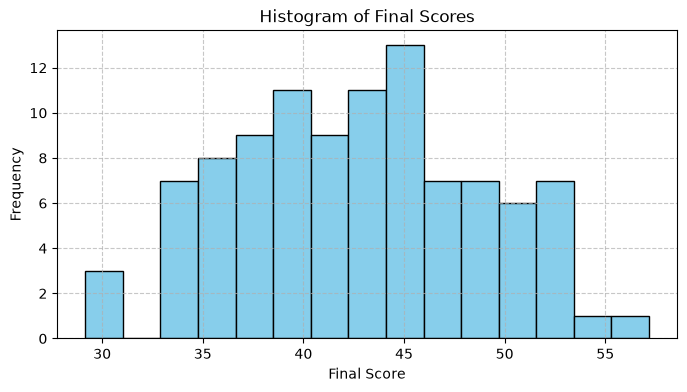

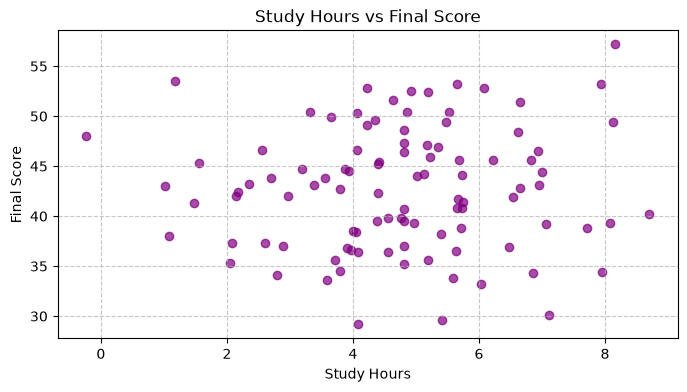

--- PART D: CORRELATION ---
Pearson correlation coefficient between study_hours and final_score: 0.0497

--- PART E: VECTORS & DOT PRODUCT ---
Feature vector x: [ 4.8123416  70.84629258 75.36681041]
Calculated prediction y: 51.72215347600458 

--- PART F: SCALING ---
Scaled features head:
   study_hours_scaled  previous_mark_scaled
0            0.039268              0.270124
1            0.039268              0.457342
2            0.039268              0.939012
3            0.039268              0.912037
4            0.039268             -1.330433


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Dataset Generation ---
np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50      # Outlier
df.loc[98, 'attendance'] = -10      # Impossible value


# --- Part A: Inspect and Clean ---
print("--- PART A: CLEANING ---")
print("Missing values before cleaning:\n", df.isnull().sum())

# Calculate medians for imputation
median_study = df['study_hours'].median()
valid_attendance = df['attendance'][df['attendance'] >= 0]
median_attendance = valid_attendance.median()

# Clean the dataset (updated to avoid Pandas ChainedAssignmentError)
df['study_hours'] = df['study_hours'].fillna(median_study)
df.loc[df['study_hours'] > 20, 'study_hours'] = median_study
df.loc[df['attendance'] < 0, 'attendance'] = median_attendance

print("Data cleaning complete. Missing values remaining:", df.isnull().sum().sum())

# Feature matrix shape, numerical columns, target variable
features = df[['study_hours', 'attendance', 'previous_mark']]
print("Shape of feature matrix:", features.shape)
print("Numerical columns:", list(df.select_dtypes(include=[np.number]).columns))
print("Target variable: final_score\n")


# --- Part B: Summarize ---
print("--- PART B: SUMMARY STATISTICS ---")
summary_table = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Standard Deviation': df.std()
})
print(summary_table, "\n")


# --- Part C: Visualize ---
# 1. Histogram for final_score
plt.figure(figsize=(8, 4))
plt.hist(df['final_score'], bins=15, edgecolor='black', color='skyblue')
plt.title('Histogram of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 2. Scatter plot of study_hours vs final_score
plt.figure(figsize=(8, 4))
plt.scatter(df['study_hours'], df['final_score'], color='purple', alpha=0.7)
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# --- Part D: Correlation ---
print("--- PART D: CORRELATION ---")
correlation = df['study_hours'].corr(df['final_score'])
print(f"Pearson correlation coefficient between study_hours and final_score: {correlation:.4f}\n")


# --- Part E: Vectors and Dot Product ---
print("--- PART E: VECTORS & DOT PRODUCT ---")
# 1. Select one student row features (excluding target) as vector x
x = df[['study_hours', 'attendance', 'previous_mark']].iloc[0].values

# 2. Define weight vector w and bias b
w = np.array([0.5, 0.2, 0.4])
b = 5

# 3. Calculate y = w . x + b using NumPy dot product
y_pred = np.dot(w, x) + b

print("Feature vector x:", x)
print("Calculated prediction y:", y_pred, "\n")


# --- Part F: Scaling ---
print("--- PART F: SCALING ---")
# 1. Standardize study_hours and previous_mark
df['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

print("Scaled features head:")
print(df[['study_hours_scaled', 'previous_mark_scaled']].head())